# Aula 11 — Fundamentos de AED e Estatística Descritiva (Teórica) · Conteúdo

**Unidade 3 — Análise Exploratória de Dados e Visualização** · ver também: [exercícios](exercicios.ipynb) · [atividades](atividades.ipynb)

**📈 Aula 11 — Fundamentos de AED e Estatística Descritiva (Teórica)**

Primeira aula da Unidade 3 (Análise Exploratória de Dados e Visualização). Medidas de tendência central e dispersão; distribuições; correlações (Pearson, Spearman); matriz de correlação; formulação de hipóteses exploratórias. Exemplos com **dados sintéticos de fácil entendimento** — desempenho de estudantes de um curso fictício e vendas de uma sorveteria no verão (nenhum dado é real). Recursos: apostila/slides, Jupyter Notebook. Avaliação: **formulário avaliativo com 20 questões** — prazo de envio até 10/11/2026. O exercício prático é para treino e **não precisa ser entregue**. Materiais desta aula: livro Tópicos de Estudo (5 capítulos) · apostila completa em PDF · pacote com notebooks e datasets · formulário avaliativo.

---
## Tópicos de Estudo — Aula 11

### Descrição

Resumo dos principais tópicos da Aula 11 — Fundamentos de AED e Estatística Descritiva, em 5 capítulos curtos.

### 1. Análise exploratória e tipos de variáveis

A **Análise Exploratória de Dados (AED)** — *Exploratory Data Analysis*, termo popularizado por John Tukey — é a etapa em que olhamos os dados com **resumos numéricos** e **gráficos simples** antes de qualquer modelo. O objetivo é conhecer os dados, encontrar padrões e problemas e, principalmente, formular **boas perguntas**.

#### O dataset da aula (sintético)

300 estudantes de um curso fictício: horas de estudo por semana, horas de sono, tempo de celular, faltas, deslocamento, mês de nascimento, turno, se trabalha e nota final (0 a 10). No exercício, 90 dias de uma sorveteria fictícia.

#### Tipos de variáveis

|              |                     |                                  |
|--------------|---------------------|----------------------------------|
| Tipo         | Subtipo             | Exemplo                          |
| Qualitativa  | nominal (sem ordem) | turno, trabalha                  |
| Qualitativa  | ordinal (com ordem) | conceito A/B/C, satisfação       |
| Quantitativa | discreta (contagem) | faltas, sorvetes vendidos        |
| Quantitativa | contínua (medida)   | horas de sono, temperatura, nota |

**Atenção:** o tipo no Pandas não é o tipo estatístico. `mes_nascimento` é `int64`, mas a "média do mês de nascimento" não tem significado útil.

In [ ]:
df.dtypes
df["turno"].value_counts(normalize=True)   # proporções de uma variável qualitativa

### 2. Medidas de tendência central

Respondem à pergunta **"qual é o valor típico?"**

- **Média** (`mean`) — soma ÷ quantidade; usa todos os valores, mas é sensível a extremos.
- **Mediana** (`median`) — valor central dos dados ordenados; robusta a extremos.
- **Moda** (`mode`) — valor mais frequente; a única que serve para variáveis nominais.

|                        |       |         |
|------------------------|-------|---------|
| Variável               | Média | Mediana |
| nota final             | 5,69  | 5,80    |
| horas de sono          | 7,06  | 7,10    |
| horas de estudo/semana | 7,34  | 6,25    |
| deslocamento (min)     | 26,0  | 23,0    |

Quando a **média é bem maior que a mediana**, há uma cauda à direita: poucos valores altos puxam a média. Nesse caso, a mediana descreve melhor o caso típico.

#### Um único valor extremo

Incluir um registro errado de 150 h de estudo muda a média de 7,34 para 7,81 h; a mediana vai de 6,25 para 6,30 h. Na sorveteria, o dia do festival (1.150 sorvetes) eleva a média de 166,7 para 177,6 sorvetes, enquanto a mediana fica em torno de 174.

### 3. Medidas de dispersão

Duas turmas podem ter a mesma média e ser muito diferentes. A dispersão mede **o quanto os valores se espalham**.

|  |  |  |
|----|----|----|
| Medida | Ideia | Pandas |
| Amplitude | máximo − mínimo (frágil: usa 2 valores) | `s.max() - s.min()` |
| Variância | média dos quadrados dos desvios (unidade²) | `s.var()` |
| Desvio-padrão | raiz da variância (mesma unidade) | `s.std()` |
| Coeficiente de variação | desvio ÷ média × 100% (sem unidade) | `s.std() / s.mean() * 100` |
| Intervalo interquartil | Q3 − Q1 (50% centrais; robusto) | `s.quantile(.75) - s.quantile(.25)` |

O Pandas usa a versão **amostral** (divide por n − 1).

#### No laboratório

- Sono: desvio 0,86 h e CV ≈ 12% — quase todos dormem entre 6 e 8 h.
- Estudo: desvio 5,04 h e CV ≈ 69% — muita variação entre estudantes.
- Nota: Q1 = 4,7, Q3 = 6,6 → IQR = 1,9.

**Regra prática:** distribuição aproximadamente simétrica → média e desvio-padrão; assimétrica ou com extremos → mediana e IQR. O `describe()` traz os cinco números de Tukey (mínimo, Q1, mediana, Q3, máximo), a média e o desvio.

### 4. Distribuições: forma, assimetria e boxplot

A **distribuição** mostra como os valores se espalham na escala. Use **histogramas** e **boxplots**.

- **Simétrica** — média ≈ mediana; assimetria (`skew`) ≈ 0. Ex.: horas de sono (0,20).
- **Assimétrica à direita** — cauda para valores altos; média \> mediana; skew \> 0. Ex.: horas de estudo (1,51), chuva diária (2,3).
- **Assimétrica à esquerda** — cauda para valores baixos; média \< mediana; skew \< 0.

A **curtose** (`kurt`, excesso em relação à normal) indica caudas mais pesadas (\> 0) ou mais leves (\< 0).

#### Regra 68–95–99,7

Em uma distribuição aproximadamente **normal**, cerca de 68%, 95% e 99,7% dos valores ficam a 1, 2 e 3 desvios da média. Para o sono (média 7,06 h, desvio 0,86 h): 64,7% entre 6,21 e 7,92 h; 95,3% entre 5,35 e 8,78 h. A regra **não** vale bem para distribuições assimétricas.

#### Boxplot

A caixa vai de Q1 a Q3, a linha interna é a mediana, os bigodes vão até o último valor dentro de 1,5·IQR e os pontos além disso são **candidatos a outlier**. Boxplots lado a lado comparam grupos: quem trabalha tem nota mediana 5,10; quem não trabalha, 6,05.

In [ ]:
df.groupby("trabalha")["nota_final"].agg(["mean", "median", "std"])

### 5. Correlação, matriz de correlação e hipóteses

O **gráfico de dispersão** vem primeiro. A **correlação** resume força e direção da associação entre −1 e +1.

|  |  |  |
|----|----|----|
| Coeficiente | Mede | Pandas |
| Pearson (r) | associação **linear** | `x.corr(y)` |
| Spearman (ρ) | associação **monotônica** (Pearson nos postos) | `x.corr(y, method="spearman")` |

Leitura aproximada de \|r\|: \< 0,1 desprezível · 0,1–0,3 fraca · 0,3–0,5 moderada · 0,5–0,7 forte · \> 0,7 muito forte.

- Estudo × nota: r = 0,68 e ρ = 0,72 — relação crescente, mas curva (ganho decrescente).
- Faltas × nota: ρ = −0,40 (negativa moderada). Mês de nascimento × nota: ≈ 0.
- Sorveteria: temperatura × sorvetes deu r = 0,32 e ρ = 0,80 por causa de **um** dia de festival; sem ele, r = 0,85.
- r ≈ 0 indica ausência de relação *linear* — uma relação em U pode ter r ≈ 0.

#### Matriz de correlação

In [ ]:
df[numericas].corr(method="spearman")   # simétrica, diagonal = 1

#### Correlação não é causalidade

O turno da noite tem notas menores, mas, separando quem trabalha, as diferenças entre turnos quase somem: **trabalhar** é uma variável de confusão.

#### Hipóteses exploratórias

A AED termina com hipóteses **específicas, mensuráveis e verificáveis**. Ex.: "Mais horas de estudo estão associadas a notas maiores, com ganho decrescente" (ρ = 0,72). São evidências exploratórias, não provas: serão investigadas nas próximas análises.

---
## Conteúdo — Aula 11 (PDF)

> Apostila completa da Aula 11 — Fundamentos de AED e Estatística Descritiva: tipos de variáveis, tendência central, dispersão, distribuições, correlações de Pearson e Spearman, matriz de correlação, correlação × causalidade e hipóteses exploratórias, com exemplo guiado, exercício prático e colinha.

> Convertido de [`Aula11_AED_Estatistica_Descritiva.pdf`](Aula11_AED_Estatistica_Descritiva.pdf) (o original está nesta pasta — confira nele figuras e diagramação).

INSTITUTO FEDERAL DE EDUCAÇÃO, CIÊNCIA E TECNOLOGIA DO RIO GRANDE DO NORTE ESPECIALIZAÇÃO EM CIÊNCIA DE DADOS  ·  DISCIPLINA: ANÁLISE E CIÊNCIA DE DADOS

### Aula 11 - Fundamentos de AED e Estatística Descritiva

Medidas de tendência central e dispersão; distribuições; correlações (Pearson, Spearman); matriz de correlação; formulação de hipóteses exploratórias

Unidade

Natureza Unidade 3 - Análise Exploratória de Dados e Visualização (Aula 11, primeira aula da unidade)

Aula teórica, com exemplos em Jupyter Notebook

Carga horária

4 h/a - 3 h de exposição + 1 h de exemplos guiados

Pré-

requisitos

Recursos

Avaliação

Professor Aulas 04-05 (Pandas) e 09-10 (qualidade, limpeza e pipeline de dados)

Slides/apostila, Jupyter Notebook, pandas , numpy , matplotlib , scipy ; dados sintéticos

Formulário avaliativo (20 questões) - prazo 10/11/2026. O exercício prático é para treino e não precisa ser entregue.

Plácido Antônio de Souza Neto

### Objetivos de aprendizagem

Ao final desta aula, espera-se que o estudante seja capaz de:

1. Explicar o papel da Análise Exploratória de Dados (AED) e classificar variáveis em qualitativas (nominais/ordinais) e quantitativas (discretas/contínuas).
2. Calcular e interpretar medidas de tendência central (média, mediana, moda) e escolher a mais adequada.
3. Calcular e interpretar medidas de dispersão (amplitude, variância, desvio-padrão, coeficiente de variação, IQR).
4. Descrever a forma de uma distribuição com histograma, boxplot, assimetria e curtose, e aplicar a regra 68-95-99,7.
5. Medir associações com os coeficientes de Pearson e Spearman, ler uma matriz de correlação e reconhecer o efeito de outliers.
6. Distinguir correlação de causalidade e formular hipóteses exploratórias específicas e testáveis.

### Sumário

### Parte I - Fundamentos

1.1 O que é Análise Exploratória de Dados

- 1.2 Tipos de variáveis
- 1.3 Medidas de tendência central
- 1.4 Medidas de dispersão
- 1.5 Distribuições: forma, assimetria e boxplot
- 1.6 Correlação: Pearson e Spearman
- 1.7 Matriz de correlação
- 1.8 Correlação não é causalidade
- 1.9 Hipóteses exploratórias

Parte II - Exemplo guiado: desempenho de estudantes

Parte III - Exercício prático: o verão da sorveteria (sem entrega)

Parte IV - Formulário avaliativo

Apêndice A - Colinha de estatística descritiva com Pandas

Apêndice B - Referências

### SOBRE OS DADOS USADOS NESTA AULA

Os dois conjuntos são sintéticos e foram escolhidos por serem de fácil entendimento: 300 estudantes de um curso fictício (horas de estudo, sono, celular, faltas, deslocamento, turno, se trabalha e nota final) e 90 dias de uma sorveteria fictícia (temperatura, chuva, sorvetes e cafés vendidos). Foram gerados por gerar\_dados.py (semente fixa) para ilustrar cada conceito - incluindo relações não lineares, variáveis sem relação, uma variável de confusão e um dia atípico. Nenhum registro corresponde a pessoa ou empresa real.

### Parte I - Fundamentos

Resumir, visualizar e perguntar: o que os dados dizem antes de qualquer modelo

### 1.1 O que é Análise Exploratória de Dados

Na Unidade 2 aprendemos a obter e preparar dados. A Unidade 3 começa a entendê-los . A Análise Exploratória de Dados (AED, ou EDA ), termo popularizado por John Tukey em 1977, é a etapa em que olhamos os dados com resumos numéricos e gráficos simples , com a mente aberta, antes de qualquer modelo. Ela serve para:

- conhecer as variáveis: valores típicos, variação, forma;
- detectar problemas que escaparam da limpeza (valores impossíveis, dias atípicos);
- descobrir padrões e associações entre variáveis;
- formular hipóteses que orientam as análises e os modelos seguintes.

A AED se apoia na estatística descritiva , que resume os dados observados. Ela é diferente da estatística inferencial , que usa uma amostra para tirar conclusões sobre uma população (com testes e intervalos de confiança).

### 1.2 Tipos de variáveis

O tipo da variável define quais resumos e gráficos fazem sentido:

| Tipo | Subtipo | Exemplos nos dados | Resumos adequados |
|--------------------------|---------------------|-------------------------------------------|---------------------------------|
| Qualitativa (categórica) | nominal - sem ordem | turno , trabalha , dia_semana | frequências, proporções, moda |
| | ordinal - com ordem | conceito A/B/C, nível de satisfação | frequências, moda, mediana |
| Quantitativa (numérica) | discreta - contagem | faltas , sorvetes_vendidos | média, mediana, desvio, quartis |
| | contínua - medida | horas_sono , temperatura_max , nota_final | média, mediana, desvio, quartis |

### O TIPO NO PANDAS NÃO É O TIPO ESTATÍSTICO

A coluna mes\_nascimento (1 a 12) é int64 , mas a "média do mês de nascimento" não tem interpretação útil. Códigos numéricos (CEP , matrícula, código de município) também não são quantidades. Pense sempre no significado da variável.

### 1.3 Medidas de tendência central

Respondem à pergunta "qual é o valor típico?"

| Medida | Definição | Pandas | Característica |
|----------|-----------------------------------------------------------|------------|-------------------------------------------|
| Média | soma dos valores ÷ quantidade | s.mean() | usa todos os valores; sensível a extremos |
| Mediana | valor central dos dados ordenados (50% abaixo, 50% acima) | s.median() | robusta a extremos |
| Moda | valor mais frequente | s.mode() | única que serve para variáveis nominais |

### No exemplo guiado:

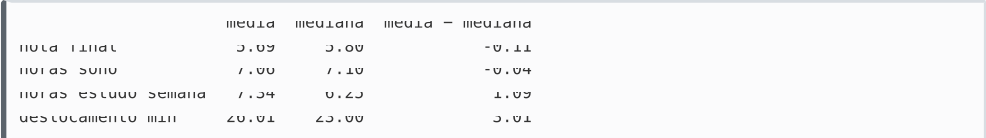

Nota e sono têm média ≈ mediana (distribuições simétricas). Horas de estudo e deslocamento têm média bem maior que a mediana : poucos estudantes que estudam muito (até 34 h/semana) ou moram longe puxam a média para cima. Nesses casos, a mediana representa melhor o estudante típico.

Sensibilidade a extremos. Incluir um único registro errado de 150 h de estudo muda a média de 7,34 para 7,81 h, enquanto a mediana vai de 6,25 para 6,30 h. Na sorveteria, o dia do festival (1.150 sorvetes) eleva a média de 166,7 para 177,6 sorvetes/dia; a mediana passa de 174,0 para 174,5.

### 1.4 Medidas de dispersão

Duas turmas podem ter a mesma média e ser muito diferentes. As medidas de dispersão dizem o quanto os valores se espalham :

| Medida | Fórmula / ideia | Fórmula / ideia | Fórmula / ideia | Pandas | Pandas | Pandas | Pandas | Observação |
|------------------------------|-------------------------|-------------------------|-------------------------|-----------------------------------|-----------------------------------|-----------------------------------|-----------------------------------|--------------------------------|
| Amplitude | máximo - mínimo | máximo - mínimo | máximo - mínimo | s.max() - s.min() | s.max() - s.min() | s.max() - s.min() | s.max() - s.min() | depende de só 2 valores |
| Variância | Σ(x - média)² ÷ (n - 1) | Σ(x - média)² ÷ (n - 1) | Σ(x - média)² ÷ (n - 1) | s.var() | s.var() | s.var() | s.var() | unidade ao quadrado |
| Desvio-padrão | √variância | √variância | √variância | s.std() | s.std() | s.std() | s.std() | mesma unidade dos dados |
| Coef. de variação (CV) | desvio ÷ média 100% | desvio ÷ média 100% | × | s.std() / s.mean() * 100 | s.std() / s.mean() * 100 | s.std() / s.mean() * 100 | s.std() / s.mean() * 100 | sem unidade; compara variáveis |
| Intervalo interquartil (IQR) | Q3 - Q1 | Q3 - Q1 | Q3 - Q1 | s.quantile(.75) - s.quantile(.25) | s.quantile(.75) - s.quantile(.25) | s.quantile(.75) - s.quantile(.25) | s.quantile(.75) - s.quantile(.25) | 50% centrais; robusto |
| | mín | máx | amplitude | variância | desvio | CV (%) | Q1 | Q3 IQR |
| nota_final | 1.5 | 9.6 | 8.1 | 1.84 | 1.36 | 23.83 | 4.7 | 6.60 1.90 |
| horas_sono | 5.1 | 9.4 | 4.3 | 0.74 | 0.86 | 12.15 | 6.4 | 7.60 1.20 |
| horas_estudo_semana | 0.4 | 34.2 | 33.8 | 25.43 | 5.04 | 68.74 | 3.8 | 9.60 5.80 |
| faltas | 0.0 | 11.0 | 11.0 | 5.32 | 2.31 | 54.37 | 2.0 | 6.00 4.00 |

O sono varia pouco (CV ≈ 12%), as horas de estudo variam muito (CV ≈ 69%). O CV permite essa comparação mesmo entre variáveis com unidades diferentes. O Pandas usa a fórmula amostral (divide por n - 1 ).

### QUAL PAR DE MEDIDAS USAR?

Distribuição aproximadamente simétrica, sem extremos → média e desvio-padrão . Distribuição assimétrica ou com valores extremos → mediana e IQR . O describe() mostra os cinco números de Tukey (mínimo, Q1, mediana, Q3, máximo), a média e o desvio.

### 1.5 Distribuições: forma, assimetria e boxplot

A distribuição descreve como os valores se espalham ao longo da escala. O histograma divide a escala em intervalos e mostra quantas observações caem em cada um.

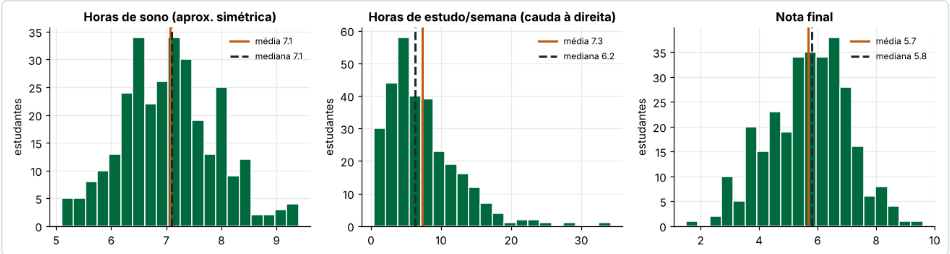

Figura 1 - Sono (aprox. simétrico), estudo (cauda à direita) e nota final. Linha contínua: média; tracejada: mediana.

| Forma | Média × mediana | Assimetria (skew) | Exemplo |
|-----------------------------------|-------------------|---------------------|--------------------------------------------|
| Simétrica | média ≈ mediana | ≈ 0 | horas de sono (0,20), nota (-0,16) |
| Assimétrica à direita (positiva) | média > mediana | > 0 | horas de estudo (1,51), chuva diária (2,3) |
| Assimétrica à esquerda (negativa) | média < mediana | < 0 | nota de uma prova muito fácil |

A curtose ( kurt() , excesso em relação à normal) descreve o peso das caudas: perto de 0, caudas como as da normal; positiva, mais valores extremos. As horas de estudo têm curtose 3,56.

### A distribuição normal e a regra 68-95-99,7

Na distribuição normal (em forma de sino), cerca de 68% dos valores ficam a 1 desvio da média, 95% a 2 desvios e 99,7% a 3 desvios. As horas de sono (média 7,06 h; desvio 0,86 h) seguem bem a regra:

```
±1 desvio(s): [6.21, 7.92] h → 64.7% dos estudantes
±2 desvio(s): [5.35, 8.78] h → 95.3% dos estudantes
±3 desvio(s): [4.49, 9.64] h → 100.0% dos estudantes
```

Em distribuições assimétricas, como as horas de estudo, a regra não se aplica - mais um motivo para olhar a forma antes de resumir.

### Boxplot

O boxplot desenha os cinco números: a caixa vai de Q1 a Q3 (o IQR), a linha interna é a mediana, os bigodes vão até o último valor dentro de 1,5·IQR e os pontos além disso são candidatos a outlier (Aula 09). É a melhor forma de comparar grupos .

Figura 2 - Nota final por situação de trabalho (mediana 6,05 × 5,10) e tempo de deslocamento, com cauda à direita.

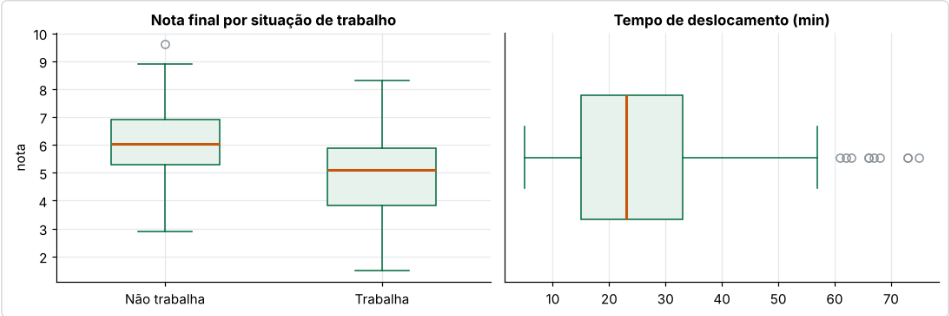

### 1.6 Correlação: Pearson e Spearman

Para duas variáveis quantitativas, o primeiro passo é o gráfico de dispersão . A correlação resume a associação em um número entre -1 e +1: o sinal indica a direção e o valor absoluto , a força.

| Coeficiente | Mede | Como calcula | Quando usar |
|---------------|-----------------------|----------------------------------------|--------------------------------------------------------------------------|
| Pearson (r) | associação linear | cov(x, y) ÷ (desvio x · desvio y ) | relação em linha reta, sem outliers fortes |
| Spearman (ρ) | associação monotônica | Pearson aplicado aos postos (rankings) | relação curva mas sempre crescente/decrescente; dados ordinais; outliers |

Guia aproximado de leitura de |r|: &lt; 0,1 desprezível · 0,1-0,3 fraca · 0,3-0,5 moderada · 0,5-0,7 forte · &gt; 0,7 muito forte.

Figura 3 - Estudo × nota (positiva, forte e curva), faltas × nota (negativa, moderada) e mês de nascimento × nota (sem relação).

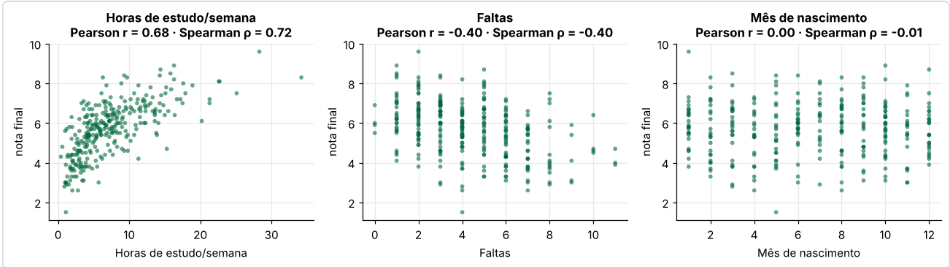

- Estudo × nota: r = 0,68 e ρ = 0,72. A nuvem curva : as primeiras horas de estudo ajudam muito e as seguintes cada vez menos. Como a relação é monotônica, mas não linear, ρ &gt; r.
- Faltas × nota: r = ρ = -0,40 (negativa moderada).

- Mês de nascimento × nota: ≈ 0. Atenção: r ≈ 0 significa ausência de relação linear ; uma relação em forma de U pode ter r ≈ 0 - só o gráfico revela.

### O efeito de um outlier

Na sorveteria, temperatura × sorvetes dá r = 0,32 e ρ = 0,80 . A discordância vem de um único dia : um sábado de festival, relativamente fresco (21,8 °C), com 1.150 sorvetes. Sem ele, r = 0,85 e ρ = 0,86. O Spearman, baseado em postos, é robusto: o outlier vira apenas "o maior valor".

Figura 4 - Temperatura × vendas de sorvete: o ponto isolado no alto é o dia do festival.

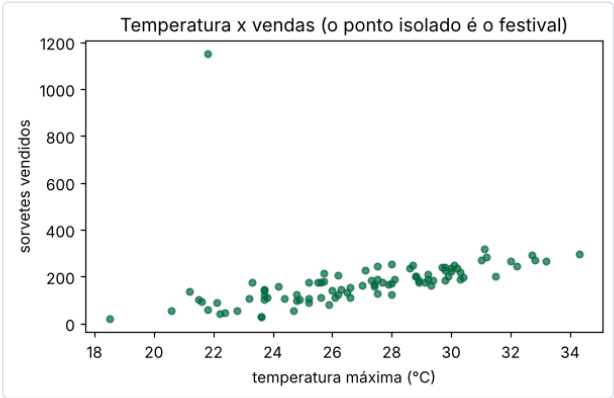

O scipy.stats.pearsonr e o spearmanr retornam também o p-valor , que indica se uma correlação daquele tamanho seria improvável caso não houvesse associação na população. Por ora, use-o apenas como indicativo; testes de hipóteses exigem cuidados que veremos adiante.

### 1.7 Matriz de correlação

Com muitas variáveis numéricas, df.corr() (ou df.corr(method="spearman") ) calcula todas as correlações par a par. A matriz é simétrica e a diagonal vale 1 . Um mapa de calor com escala divergente (âmbar para negativo, cinza no zero, verde para positivo) facilita a leitura.

Figura 5 - Matriz de correlação de Spearman das variáveis numéricas dos estudantes.

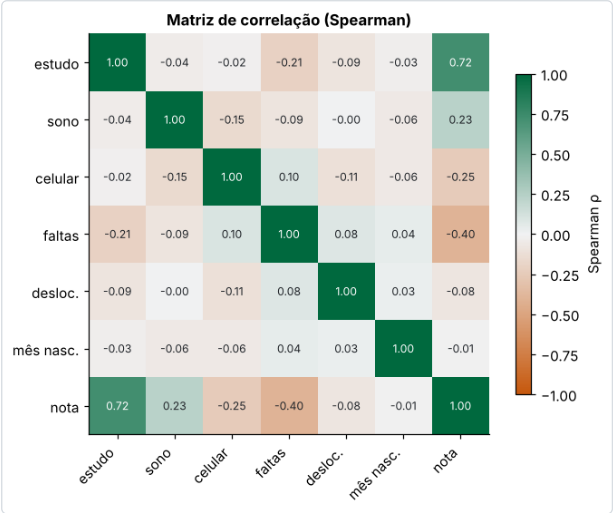

Como ler: (1) procure as correlações mais fortes com a variável de interesse (nota: estudo 0,72; faltas -0,40); (2) veja se variáveis explicativas são muito correlacionadas entre si (redundância); (3) note as que não se relacionam com nada (mês de nascimento).

### 1.8 Correlação não é causalidade

Uma correlação mostra que duas variáveis variam juntas , não que uma causa a outra. Explicações possíveis: (1) causa direta; (2) uma variável de confusão ( confounder ) que afeta as duas; (3) coincidência.

Exemplo do laboratório: o turno da noite tem nota média menor (5,32 contra 5,87 da manhã). Mas, separando por situação de trabalho:

| trabalha turno | Não | Sim | n (trabalha) | n (não trabalha) |
|------------------|-------|-------|----------------|--------------------|
| Manhã | 5.99 | 4.93 | 13 | 101 |
| Tarde | 6.05 | 4.72 | 20 | 82 |
| Noite | 6.36 | 5.01 | 65 | 19 |

Dentro de cada grupo, as notas dos turnos ficam parecidas. O turno da noite concentra quem trabalha, e são esses estudantes que têm notas menores: trabalhar é a variável de confusão. Essa técnica - comparar dentro de grupos - chama-se estratificação .

### 1.9 Hipóteses exploratórias

A AED termina com perguntas melhores . Uma hipótese exploratória é uma afirmação sugerida pelos dados, que orienta as próximas análises. Uma boa hipótese é específica

(quais variáveis, qual direção), mensurável com os dados disponíveis e indica como será verificada .

| # | Hipótese exploratória | Evidência descritiva |
|-----|------------------------------------------------------------------------------|-----------------------------------------------------------------------|
| H1 | Mais horas de estudo estão associadas a notas maiores, com ganho decrescente | ρ = 0,72; nuvem curva; mediana por faixa: 4,1 → 5,4 → 6,1 → 6,7 → 7,5 |
| H2 | Quem trabalha tem nota menor, em parte por estudar e dormir menos | ≈ 1 ponto a menos; 3 h a menos de estudo; 0,5 h a menos de sono |
| H3 | A diferença entre turnos desaparece quando se considera o trabalho | notas parecidas dentro de cada grupo |
| H4 | Mais faltas estão associadas a notas menores | ρ = -0,40 |

### EVIDÊNCIA EXPLORATÓRIA NÃO É PROVA

Hipóteses ruins: "os dados são interessantes" (vaga), "está provado que trabalhar causa notas baixas" (afirma prova), "vamos calcular tudo" (procedimento, não hipótese). A AED sugere ; a confirmação vem de análises e modelos adequados.

### Parte II - Exemplo guiado: desempenho de estudantes

Notebook Aula11\_AED\_Estatistica\_Descritiva.ipynb - todas as saídas são reais

O notebook percorre todos os conceitos da Parte I com desempenho\_estudantes.csv (300 estudantes, 10 colunas). Roteiro:

| # | Parte | O que é feito |
|-----|----------------------|----------------------------------------------------------------------------------------------------------|
| 1 | Tipos de variáveis | dtypes , frequências e proporções de turno e trabalho |
| 2 | Tendência central | média × mediana; moda; experimento com um valor extremo (150 h) |
| 3 | Dispersão | função dispersao() com amplitude, variância, desvio, CV e IQR; describe() |
| 4 | Distribuições | histogramas com média e mediana; skew e kurt ; regra 68-95- 99,7; boxplots |
| 5 | Comparação de grupos | groupby().agg() por trabalho e por turno |
| 6 | Correlação | dispersões; Pearson e Spearman com corr() e scipy.stats ; efeito de um registro errado (36 h de celular) |
| 7 | Matriz de correlação | matriz de Spearman, heatmap e ranking dos pares mais fortes |
| 8 | Causalidade | pivot_table turno × trabalho (variável de confusão) |
| 9 | Hipóteses | quadro de hipóteses e verificação da H1 por faixas de estudo ( pd.cut ) |

Destaque - um único registro digitado errado (36 h de celular por dia, com nota 9,5) quase apaga a correlação de Pearson, enquanto o Spearman resiste:

```
Sem o outlier → Pearson -0.27 | Spearman -0.25
Com o outlier → Pearson -0.03 | Spearman -0.24
```

### Parte III - Exercício prático: o verão da sorveteria

Notebook Aula11\_Exercicio\_Pratico.ipynb - para treinar, sem entrega

Nove passos curtos com sorveteria.csv (90 dias). Cada passo traz um bloco "Para conferir":

| # | Passo | Para conferir |
|-----|------------------------------------------|------------------------------------------------------|
| 1 | Carregar e classificar as variáveis | 90 × 7; nominais, discretas e contínuas |
| 2 | Média e mediana; dia de maior venda | sorvetes: 177,6 × 174,5; máximo 1.150 (festival) |
| 3 | Recalcular sem o dia atípico | média 166,7; mediana 174,0 |
| 4 | Desvio, CV e IQR | temperatura CV 12%; sorvetes CV 41% |
| 5 | Forma da chuva | 67 dias sem chuva; skew ≈ 2,3; média 3,3 × mediana 0 |
| 6 | Fim de semana × dias úteis | mediana 202 × 160 sorvetes |
| 7 | Pearson × Spearman, com e sem o festival | 0,32 × 0,80 → 0,85 × 0,86 |
| 8 | Matriz de correlação | temperatura × cafés ≈ -0,76; chuva × cafés ≈ 0,49 |
| 9 | Duas hipóteses exploratórias | exemplos no notebook |


> **Parte avaliativa desta apostila → [atividades.ipynb](atividades.ipynb).**

### Apêndice A - Colinha de estatística descritiva com Pandas

| Tarefa | Código |
|--------------------------|--------------------------------------------------------------------|
| Frequências / proporções | s.value_counts() · s.value_counts(normalize=True) |
| Média, mediana, moda | s.mean() · s.median() · s.mode()[0] |
| Variância, desvio | s.var() · s.std() (amostrais, n - 1) |
| Coeficiente de variação | s.std() / s.mean() * 100 |
| Quartis e IQR | q1, q3 = s.quantile([.25, .75]) · q3 - q1 |
| Resumo geral | df.describe() |
| Assimetria, curtose | s.skew() · s.kurt() |
| Histograma | plt.hist(s, bins=20) · s.plot.hist() |
| Boxplot por grupo | df.boxplot(column="y", by="grupo") |
| Comparar grupos | df.groupby("g")["y"].agg(["mean", "median", "std"]) |
| Correlação | x.corr(y) · x.corr(y, method="spearman") |
| Com p-valor | stats.pearsonr(x, y) · stats.spearmanr(x, y) |
| Matriz | df[cols].corr(method="spearman") |
| Estratificar | df.pivot_table(index="a", columns="b", values="y", aggfunc="mean") |

### Apêndice B - Referências

- TUKEY, John W. Exploratory Data Analysis . Reading: Addison-Wesley, 1977.
- BUSSAB, Wilton O.; MORETTIN, Pedro A. Estatística Básica . 9. ed. São Paulo: Saraiva, 2017. Caps. 2 a 4.
- BRUCE, Peter; BRUCE, Andrew; GEDECK, Peter. Estatística Prática para Cientistas de Dados . 2. ed. Rio de Janeiro: Alta Books, 2021. Cap. 1 (Análise exploratória de dados).
- McKINNEY, Wes. Python para Análise de Dados . 3. ed. São Paulo: Novatec, 2023. Caps. 5 e 10.
- PANDAS. Descriptive statistics . pandas.pydata.org/docs/user\_guide/basics.html
- SCIPY. Statistical functions (scipy.stats) . docs.scipy.org/doc/scipy/reference/stats.html